# Tokenisateurs comparés — WordPiece et Unigram, les deux autres familles de sous-mots

Le [04-Tokenisation](04-Tokenisation-From-Scratch.ipynb) a construit un **BPE** à la main : fusionner la paire de symboles la plus **fréquente**, encore et encore. C'est une famille — la plus répandue (GPT, Qwen, Llama côté BPE bytes) — mais pas la seule. Ce notebook construit à la main les deux autres grandes familles de sous-mots :

- **WordPiece** (BERT, DistilBERT, Electra) : même boucle de fusions, mais le critère est la **cohésion** — une paire est choisie si elle apparaît souvent *par rapport à ce que ses moitiés font séparément* ;
- **Unigram** (SentencePiece, T5, les Llama récents) : la logique **inverse** — partir d'un vocabulaire surdimensionné de candidats et **élaguer** par vraisemblance.

Les trois familles sont construites **sur le même corpus** (les fables du 04), comparées **à budget de vocabulaire égal**, confrontées à la **bibliothèque réelle** `tokenizers` (le moteur Rust derrière HuggingFace) entraînée sur ce même corpus, puis l'effet **multilingue** du choix de tokenizer est mesuré sur le coût. La question n'est pas « laquelle est la meilleure » : c'est **ce que le critère de sélection change** — quels fragments survivent, et combien coûte un texte qui n'est pas dans la langue du corpus d'entraînement.

## 1. Objectif — le critère de sélection fait la famille

Les trois familles poursuivent le même but — un vocabulaire **fermé** d'unités entre le mot et le caractère — mais leur **critère de sélection** diffère, et ce critère décide de la forme des fragments :

| Famille | Direction | Critère de sélection | Modèles emblématiques |
|---|---|---|---|
| **BPE** | ascendant (fusions) | la paire la plus **fréquente** | GPT, Qwen, Claude |
| **WordPiece** | ascendant (fusions) | la paire au meilleur score `freq(ab) / (freq(a)·freq(b))` | BERT, DistilBERT |
| **Unigram** | descendant (élagage) | la pièce qui coûte le **moins de vraisemblance** à retirer | SentencePiece, T5, Llama |

Deux lectures à garder en tête pendant les mesures :

1. à **budget de vocabulaire égal**, les trois familles produisent-elles des **longueurs** comparables — ou la famille décide-t-elle du coût ?
2. le critère change-t-il la **forme** des fragments (quels morphèmes survivent) même quand la longueur moyenne converge ?

La réponse mesurée arrive en section 5 ; l'effet sur une langue **hors corpus** en section 7.

## 2. Le même corpus, le même BPE de référence

Le corpus est **strictement celui du 04** — les mêmes fables de La Fontaine, le même découpage en mots. C'est la condition de comparabilité : ce qui varie ensuite est le **tokenizer**, jamais le texte. On reconstruit le BPE-60 du 04 comme référence (le code est repris tel quel du notebook précédent).

In [1]:
# Corpus français borné et reproductible : les mêmes fables que le 04.
FABLES_TEXT = """
Maître Corbeau, sur un arbre perché, tenait en son bec un fromage.
Maître Renard, par l'odeur alléché, lui tint à peu près ce langage.
Hé bonjour, Monsieur du Corbeau. Que vous êtes joli, que vous me semblez beau.
Sans mentir, si votre ramage se rapporte à votre plumage, vous êtes le Phénix des hôtes de ces bois.
Le corbeau, honteux et confus, jura, mais un peu tard, qu'on ne l'y prendrait plus.
La cigale ayant chanté tout l'été, se trouva fort dépourvue quand la bise fut venue.
Pas un seul petit morceau de mouche ou de vermisseau, elle alla crier famine chez la fourmi sa voisine.
Je vous paierai, lui dit-elle, avant l'août, foi d'animal, intérêt et principal.
La fourmi n'est pas prêteuse, c'est là son moindre défaut.
Que faisiez-vous au temps chaud, dit-elle à cette emprunteuse.
Nuit et jour à tout venant je chantais, ne vous déplaise.
Vous chantiez, j'en suis fort aise, eh bien dansez maintenant.
Le lièvre et la tortue firent une course, et la tortue, lente mais obstinée,
gagna contre le lièvre trop confiant.
Rien ne sert de courir, il faut partir à point, la patience vaut mieux que la force.
Le lion, roi des animaux, apprit un jour que les bêtes de son royaume le craignaient.
Le rat des villes et le rat des champs se rencontrèrent et partagèrent leur repas.
Le loup et l'agneau se désaltéraient au même ruisseau, le loup chercha une querelle à l'agneau.
Le corbeau et le renard se parlèrent longtemps, le renard eut le fromage.
Le chêne et le roseau se disputaient la force, le vent les départagea.
Perrette et le pot au lait, la poule aux œufs d'or, le coq et le renard.
Le savetier et le financier, le sage et le fou, le laboureur et ses enfants.
""".strip()

import re, collections
# Découpage en mots : lettres accentuées, apostrophe, chiffres, tiret (identique au 04).
WORDS = re.findall(r"[a-zà-ÿ'éèêëïôöûüç0-9-]+", FABLES_TEXT.lower())

def train_bpe(words, n_merges):
    # Chaque mot devient une liste de symboles ; </w> marque la fin du mot.
    word_symbols = [list(w) + ['</w>'] for w in words]
    merges = []
    for _ in range(n_merges):
        pair_counts = collections.Counter()
        for syms in word_symbols:
            for i in range(len(syms) - 1):
                pair_counts[(syms[i], syms[i + 1])] += 1
        if not pair_counts:
            break
        best = max(pair_counts, key=lambda p: (pair_counts[p], p))
        if pair_counts[best] < 2:
            break
        merges.append(best)
        new_symbols = []
        for syms in word_symbols:
            out, i = [], 0
            while i < len(syms):
                if i < len(syms) - 1 and (syms[i], syms[i + 1]) == best:
                    out.append(syms[i] + syms[i + 1]); i += 2
                else:
                    out.append(syms[i]); i += 1
            new_symbols.append(out)
        word_symbols = new_symbols
    return merges

def make_bpe(merges):
    merge_priority = {pair: i for i, pair in enumerate(merges)}
    def encode(word):
        syms = list(word) + ['</w>']
        while True:
            best_pair, best_rank = None, float('inf')
            for i in range(len(syms) - 1):
                pair = (syms[i], syms[i + 1])
                if pair in merge_priority and merge_priority[pair] < best_rank:
                    best_pair, best_rank = pair, merge_priority[pair]
            if best_pair is None:
                break
            new, i = [], 0
            while i < len(syms):
                if i < len(syms) - 1 and (syms[i], syms[i + 1]) == best_pair:
                    new.append(syms[i] + syms[i + 1]); i += 2
                else:
                    new.append(syms[i]); i += 1
            syms = new
        # retire le marqueur de fin de mot ; un marqueur resté seul produirait une
        # chaîne vide — on la filtre (elle ne code aucune lettre du mot).
        out = [s[:-len('</w>')] if s.endswith('</w>') else s for s in syms]
        return [s for s in out if s]
    return encode, (lambda tokens: ''.join(tokens))

MERGES_BPE = train_bpe(WORDS, 60)
BPE_encode, BPE_decode = make_bpe(MERGES_BPE)

CHARS = {c for w in WORDS for c in w} | {'</w>'}
bpe_tokens = sum(len(BPE_encode(w)) for w in WORDS)
print(f"Corpus : {len(WORDS)} mots, {len(set(WORDS))} distincts — les mêmes fables que le 04.")
print(f"BPE de référence (60 fusions) : {bpe_tokens} tokens, "
      f"{bpe_tokens/len(WORDS):.3f} tokens/mot, vocabulaire {len(MERGES_BPE)+len(CHARS)} symboles.")

Corpus : 299 mots, 188 distincts — les mêmes fables que le 04.
BPE de référence (60 fusions) : 871 tokens, 2.913 tokens/mot, vocabulaire 94 symboles.


### Lecture du résultat

La référence est posée : même corpus (299 mots, 188 distincts), même entraînement que le 04 — 60 fusions, 94 symboles, **871 tokens soit 2,913 tokens/mot**. Un chiffre diffère volontairement de celui du 04 (896 tokens, 2,997 tokens/mot) : l'encodeur retire ici un marqueur `</w>` resté seul, qui ne code aucune lettre du mot — 25 tokens de marqueur pur que le 04 comptait. La divergence est déclarée pour que les deux carnets restent réconciliables ; elle ne touche que le décompte, jamais l'entraînement.

## 3. WordPiece — la fusion au score de cohésion

WordPiece garde la mécanique du BPE (compter les paires, fusionner la meilleure, répéter) mais change le **choix** : la paire retenue maximise

$$\text{score}(a, b) = \frac{\text{freq}(ab)}{\text{freq}(a) \cdot \text{freq}(b)}$$

C'est une mesure de **cohésion** (une parente du PMI) : une paire est bonne si elle apparaît souvent *compte tenu de la fréquence de ses moitiés*. Une paire très fréquente dont les moitiés sont très fréquentes aussi ne marque pas ; une paire modérément fréquente mais dont les moitiés ne vivent presque que ensemble marque haut. Concrètement : le BPE fusionne d'abord ce qui est **commun** (terminaisons `e</w>`, `s</w>`), WordPiece peut préférer un digramme plus rare mais **inséparable**.

Une garde est indispensable : sans plancher de fréquence, la paire la plus cohésive serait presque toujours une paire **vue une seule fois** (score maximal par construction — ses moitiés ne vivent qu'ensemble). Le WordPieceTrainer réel a la même garde (`min_frequency`) ; on n'élit donc la plus cohésive que **parmi les paires vues au moins deux fois**.

L'encodeur est exactement celui du BPE — appliquer les fusions par ordre de priorité — seul l'apprentissage change.

In [2]:
# WordPiece : la même boucle, le critère change — cohésion freq(ab)/(freq(a)*freq(b)).
def train_wordpiece(words, n_merges):
    word_symbols = [list(w) + ['</w>'] for w in words]
    merges = []
    for _ in range(n_merges):
        pair_counts = collections.Counter()
        sym_counts = collections.Counter()
        for syms in word_symbols:
            for s in syms:
                sym_counts[s] += 1
            for i in range(len(syms) - 1):
                pair_counts[(syms[i], syms[i + 1])] += 1
        if not pair_counts:
            break
        # plancher de fréquence : la cohésion élirait sinon des paires vues une seule
        # fois (score maximal par construction) — même garde que min_frequency du
        # WordPieceTrainer réel. Parmi les paires vues >= 2 fois, on prend la plus cohésive.
        eligible = {p: c for p, c in pair_counts.items() if c >= 2}
        if not eligible:
            break
        def cohesion(p):
            return pair_counts[p] / (sym_counts[p[0]] * sym_counts[p[1]])
        # ex æquo => ordre lexical, pour rester déterministe (comme le BPE du 04)
        best = max(eligible, key=lambda p: (cohesion(p), p))
        merges.append(best)
        new_symbols = []
        for syms in word_symbols:
            out, i = [], 0
            while i < len(syms):
                if i < len(syms) - 1 and (syms[i], syms[i + 1]) == best:
                    out.append(syms[i] + syms[i + 1]); i += 2
                else:
                    out.append(syms[i]); i += 1
            new_symbols.append(out)
        word_symbols = new_symbols
    return merges

MERGES_WP = train_wordpiece(WORDS, 60)
WP_encode, WP_decode = make_bpe(MERGES_WP)   # même encodeur : seul l'ordre des fusions diffère

wp_tokens = sum(len(WP_encode(w)) for w in WORDS)
print(f"WordPiece (60 fusions) : {wp_tokens} tokens, {wp_tokens/len(WORDS):.3f} tokens/mot, "
      f"vocabulaire {len(MERGES_WP)+len(CHARS)} symboles.")
print()
print("Les 12 premières fusions, côte à côte :")
print(f"{'  BPE (fréquence)':<26}{'WordPiece (cohésion)'}")
for i in range(min(12, len(MERGES_BPE), len(MERGES_WP))):
    a, b = MERGES_BPE[i], MERGES_WP[i]
    print(f"{i+1:>2}. {a[0]} + {a[1]:<16}{b[0]} + {b[1]}")
communs = set(MERGES_BPE) & set(MERGES_WP)
print(f"\nFusions communes aux deux listes : {len(communs)} sur 60.")

WordPiece (60 fusions) : 1099 tokens, 3.676 tokens/mot, vocabulaire 94 symboles.

Les 12 premières fusions, côte à côte :
  BPE (fréquence)         WordPiece (cohésion)
 1. e + </w>            c + h
 2. t + </w>            h + é
 3. s + </w>            è + v
 4. l + e</w>           i + èv
 5. e + n               l + ièv
 6. o + u               ch + é
 7. a + u               d + é
 8. a + </w>            dé + p
 9. r + </w>            lièv + r
10. a + n               q + u
11. a + i               î + t
12. e + t</w>           ît + r

Fusions communes aux deux listes : 5 sur 60.


**Lecture chiffrée — cinq fusions communes sur soixante : deux critères, deux vocabulaires.** Les trois premières fusions disent tout : BPE commence par `e + </w>`, `t + </w>`, `s + </w>` (les terminaisons françaises, transversales à tous les mots) ; WordPiece commence par `c + h`, `h + é`, `è + v` — des paires qui n'apparaissent que dans une ou deux familles de mots, mais y sont inséparables. L'indice est lisible dans la liste : `lièv + r` en position 9 (`lièvre`, vu deux fois dans le corpus), `dé + p` (`dépourvue`, `départagea`), `ch + é` (`perché`, `alléché`) — des mots rares dont les moitiés ne vivent qu'ensemble, score de cohésion maximal. Sur 60 fusions, **5 seulement sont communes** : à corpus identique, budget identique, mécanisme identique, le critère de sélection seul produit deux vocabulaires presque disjoints.

In [3]:
# Mêmes mots, deux découpages : le critère change la forme des fragments.
test_words = ['corbeau', 'vous', 'chanté', 'prêteuse', 'renard', 'fromage', 'dépourvue', 'patience']
print(f"{'mot':<12}{'BPE (fréquence)':<30}{'WordPiece (cohésion)'}")
for w in test_words:
    print(f"{w:<12}{str(BPE_encode(w)):<30}{str(WP_encode(w))}")

mot         BPE (fréquence)               WordPiece (cohésion)
corbeau     ['c', 'orbeau']               ['corb', 'e', 'a', 'u']
vous        ['vous']                      ['vous']
chanté      ['ch', 'an', 't', 'é']        ['chan', 'té']
prêteuse    ['pr', 'êt', 'eu', 'se']      ['p', 'r', 'êt', 'e', 'u', 's', 'e']
renard      ['renard']                    ['r', 'e', 'n', 'a', 'r', 'd']
fromage     ['f', 'ro', 'm', 'age']       ['fromag', 'e']
dépourvue   ['dé', 'p', 'our', 'v', 'ue'] ['dép', 'o', 'u', 'r', 'v', 'u', 'e']
patience    ['pa', 'ti', 'en', 'c', 'e']  ['p', 'a', 't', 'i', 'e', 'n', 'c', 'e']


### Lecture du résultat — le critère décide quels mots survivent entiers

La table dit la même chose mot à mot. BPE, guidé par la fréquence, garde entiers les mots fréquents (`renard`, `vous`) et fragmente le reste économiquement (`corbeau` → 2 morceaux). WordPiece, guidé par la cohésion, a dépensé ses fusions sur d'autres familles : `renard` éclate en 6 morceaux quand `chanté` tient en 2 (`chan` + `té`) — inversions pures de la table BPE. Aucun des deux n'a tort : chacun a optimisé son critère. Ce que la section suivante mesure, c'est ce que ces choix différents coûtent **en longueur totale**.

## 4. Unigram — partir de trop grand, élaguer par vraisemblance

L'Unigram renverse la direction : au lieu de **construire** le vocabulaire fusion par fusion, il part d'un ensemble **surdimensionné** de candidats (ici : tous les sous-mots de longueur ≤ 6 du corpus) et **élimine** ceux qui servent le moins, jusqu'au budget.

Le moteur est un petit modèle de langue : chaque pièce $s$ porte une probabilité $p(s)$, et la segmentation d'un mot est celle qui **maximise le produit des probabilités** de ses pièces — trouvée par programmation dynamique (**Viterbi**). L'apprentissage alterne :

1. **segmenter** chaque mot avec les probabilités courantes (Viterbi) ;
2. **ré-estimer** les probabilités au compte des pièces effectivement utilisées (un EM) ;
3. **élaguer** au budget : garder les pièces les plus utilisées (les caractères seuls restent garantis — sinon aucun mot ne serait segmentable).

**Simplification déclarée** : SentencePiece élague en retirant la pièce dont la perte coûte le **moins de log-vraisemblance** (avec re-segmentation exacte de tout le corpus à chaque retrait) ; ici l'élagage se fait **par usage** après EM. Sur un corpus de quelques centaines de mots, l'écart est de seconde importance — la direction (descendante, probabiliste) et le résultat (quelles pièces survivent) sont fidèles.

In [4]:
# Unigram simplifié mais fidèle : Viterbi + EM + élagage par usage.
import math

MAX_PIECE = 6        # longueur maximale d'une pièce candidate
TARGET_VOCAB = 93    # même budget que BPE-60 (60 fusions + 33 symboles)
word_freq = collections.Counter(WORDS)

# (1) vocabulaire de départ surdimensionné : tous les sous-mots de longueur <= 6,
#     pondérés par la fréquence des mots qui les contiennent.
piece_counts = collections.Counter()
for w, f in word_freq.items():
    for L in range(1, MAX_PIECE + 1):
        for i in range(len(w) - L + 1):
            piece_counts[w[i:i+L]] += f
print(f"Candidats de départ : {len(piece_counts)} pièces (longueur <= {MAX_PIECE}).")

def viterbi(word, logp):
    # meilleure segmentation de word par produit de p(piece) — programmation dynamique.
    n = len(word)
    best = [None] * (n + 1)
    best[0] = (0.0, 0)
    for i in range(1, n + 1):
        for j in range(max(0, i - MAX_PIECE), i):
            piece = word[j:i]
            if piece in logp and best[j] is not None:
                sc = best[j][0] + logp[piece]
                if best[i] is None or sc > best[i][0]:
                    best[i] = (sc, j)
    if best[n] is None:
        return list(word)   # repli : les caractères sont garantis, ce cas ne survient pas
    out, i = [], n
    while i > 0:
        j = best[i][1]
        out.append(word[j:i]); i = j
    return out[::-1]

def em_refit(counts, n_iter=3):
    # segmenter avec les probas courantes, recompter les pièces, renormaliser.
    for _ in range(n_iter):
        total = sum(counts.values())
        logp = {p: math.log(c / total) for p, c in counts.items()}
        usage = collections.Counter()
        for w, f in word_freq.items():
            for piece in viterbi(w, logp):
                usage[piece] += f
        counts = collections.Counter({p: c for p, c in usage.items() if c > 0})
        # les caractères seuls restent garantis (sinon un mot deviendrait insegmentable)
        for w in word_freq:
            for c in w:
                if c not in counts:
                    counts[c] = 1
    return counts

piece_counts = em_refit(piece_counts)

# (3) élagage au budget : les pièces les plus utilisées, caractères toujours garantis.
def prune(counts, k):
    chars = {c for w in word_freq for c in w}
    ranked = sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))
    kept = set(chars)
    for piece, c in ranked:
        if len(kept) >= k:
            break
        kept.add(piece)
    return collections.Counter({p: counts[p] for p in kept})

final_counts = em_refit(prune(piece_counts, TARGET_VOCAB), n_iter=2)
UG_logp = {p: math.log(c / sum(final_counts.values())) for p, c in final_counts.items()}
def UG_encode(word):
    return viterbi(word, UG_logp)

ug_tokens = sum(len(UG_encode(w)) for w in WORDS)
print(f"Unigram (budget {len(final_counts)} pièces après EM) : {ug_tokens} tokens, "
      f"{ug_tokens/len(WORDS):.3f} tokens/mot.")
print()
print("Les 15 pièces les plus utilisées (la morphologie vue par l'Unigram) :")
for piece, c in final_counts.most_common(15):
    print(f"  {piece!r:<10} usage {c}")

Candidats de départ : 1564 pièces (longueur <= 6).
Unigram (budget 93 pièces après EM) : 850 tokens, 2.843 tokens/mot.

Les 15 pièces les plus utilisées (la morphologie vue par l'Unigram) :
  'r'        usage 62
  'n'        usage 52
  'e'        usage 51
  'i'        usage 44
  'a'        usage 43
  't'        usage 40
  'u'        usage 39
  'o'        usage 35
  'le'       usage 34
  'p'        usage 31
  's'        usage 26
  'c'        usage 25
  'm'        usage 22
  'l'        usage 19
  'et'       usage 19


**Lecture chiffrée — 1 564 candidates, 93 survivantes, 850 tokens : l'Unigram termine premier.** Le contraste de méthode est total : BPE et WordPiece *construisent* (une fusion à la fois, 60 étapes), l'Unigram *trie* (1 564 pièces candidates, élagage à 93). Et le résultat détrône les deux constructeurs : **2,843 tokens/mot contre 2,913 (BPE) et 3,676 (WordPiece)**, au même budget de vocabulaire. Les pièces les plus utilisées racontent pourquoi : les caractères seuls dominent (r : 62, n : 52, e : 51), mais juste derrière arrivent `le` (34) et `et` (19) — les mots fonctionnels très fréquents, gardés entiers parce que chaque occurrence les utilise. L'élagage par usage récompense les pièces qui **travaillent souvent**, pas celles qui fusionnent souvent.

In [5]:
# Trois familles, mêmes mots : la forme des fragments diverge.
print(f"{'mot':<12}{'BPE':<26}{'WordPiece':<26}{'Unigram'}")
for w in test_words:
    print(f"{w:<12}{str(BPE_encode(w)):<26}{str(WP_encode(w)):<26}{str(UG_encode(w))}")

mot         BPE                       WordPiece                 Unigram
corbeau     ['c', 'orbeau']           ['corb', 'e', 'a', 'u']   ['corbea', 'u']
vous        ['vous']                  ['vous']                  ['vous']
chanté      ['ch', 'an', 't', 'é']    ['chan', 'té']            ['c', 'h', 'a', 'n', 't', 'é']
prêteuse    ['pr', 'êt', 'eu', 'se']  ['p', 'r', 'êt', 'e', 'u', 's', 'e']['p', 'r', 'ê', 'te', 'u', 'se']
renard      ['renard']                ['r', 'e', 'n', 'a', 'r', 'd']['renard']
fromage     ['f', 'ro', 'm', 'age']   ['fromag', 'e']           ['fromag', 'e']
dépourvue   ['dé', 'p', 'our', 'v', 'ue']['dép', 'o', 'u', 'r', 'v', 'u', 'e']['d', 'é', 'p', 'o', 'u', 'r', 'v', 'u', 'e']
patience    ['pa', 'ti', 'en', 'c', 'e']['p', 'a', 't', 'i', 'e', 'n', 'c', 'e']['p', 'a', 't', 'i', 'e', 'n', 'ce']


### Lecture du résultat — trois découpages du même mot, trois morphologies

`corbeau` : `c + orbeau` (BPE), `corb + e + a + u` (WordPiece), `corbea + u` (Unigram) — trois découpages tous valides, aucun partagé. `chanté` est plus instructif encore : l'Unigram le laisse en 6 caractères, faute d'avoir gardé `chant` — vu une seule fois dans le corpus (`ayant chanté`), la pièce ne survit pas à un élagage par **usage**. La bibliothèque réelle (section 6), qui élague par **vraisemblance**, garde `chant + é` : la différence entre les deux critères d'élagage, visible sur un seul mot.

## 5. Trois familles, une facture — comparaison à budget égal

Les trois tokenizers partent du même corpus et visent le **même budget de vocabulaire** (~93 symboles). La mesure reprend les colonnes du 04 — vocabulaire, tokens sur le corpus, tokens par mot — et ajoute la traduction en chunks RAG (budget de contexte 128 tokens, comme au 04 §8).

In [6]:
# La facture complète : vocabulaire, tokens, tokens/mot, chunks @ 128.
MAX_TOKENS = 128
def n_chunks(n_tokens, max_tokens=MAX_TOKENS):
    return -(-n_tokens // max_tokens)

rows = []
for name, enc, vsize in [
    ('mots', lambda w: [w], len(set(WORDS))),
    ('caractères', lambda w: list(w), len({c for w in WORDS for c in w})),
    ('BPE (60 fusions)', BPE_encode, len(MERGES_BPE) + len(CHARS)),
    ('WordPiece (60 fusions)', WP_encode, len(MERGES_WP) + len(CHARS)),
    ('Unigram', UG_encode, len(final_counts)),
]:
    n = sum(len(enc(w)) for w in WORDS)
    rows.append((name, vsize, n, n / len(WORDS), n_chunks(n)))

print(f"{'tokenizer':<24}{'vocab':>7}{'tokens':>9}{'tokens/mot':>12}{f'chunks@{MAX_TOKENS}':>12}")
for name, v, n, avg, ch in rows:
    print(f"{name:<24}{v:>7}{n:>9}{avg:>12.3f}{ch:>12}")

tokenizer                 vocab   tokens  tokens/mot  chunks@128
mots                        188      299       1.000           3
caractères                   33     1313       4.391          11
BPE (60 fusions)             94      871       2.913           7
WordPiece (60 fusions)       94     1099       3.676           9
Unigram                      93      850       2.843           7


**Lecture chiffrée — la famille décide du coût : 29 % d'écart entre la meilleure et la pire, à budget identique.** `Unigram 93 | 850 | 2.843 | 7 chunks`, `BPE 94 | 871 | 2.913 | 7`, `WordPiece 94 | 1099 | 3.676 | 9` — pour des vocabulaires à un symbole près, l'écart entre extrêmes est de 1 099 − 850 = **249 tokens, soit 29 %**, et une chunk RAG de plus (9 contre 7 à budget 128). Le WordPiece de ce notebook frôle même le tokenizer-caractères (4,391 tokens/mot) : sur un corpus de 299 mots, ses fusions « rares-cohésives » économisent peu de texte. Réponse à la question 1 de la section 1 : **à budget égal, la famille n'est pas neutre sur le coût** — du moins sur un petit corpus.

Ce classement (Unigram < BPE < WordPiece) est mesuré sur **299 mots** ; il ne se transporte pas tel quel aux corpus réels, où les trois familles convergent en longueur. Ce que ce corpus borné isole, c'est le **mécanisme** : la fréquence (BPE), la cohésion (WordPiece) et l'usage (Unigram) choisissent des candidats différents — sur peu de données ces choix divergent visiblement, sur beaucoup ils se moyennent. L'autre différence entre familles ne se voit pas dans un compte de tokens : l'Unigram produit un **modèle probabiliste** (des segmentations alternatives et leur vraisemblance), quand BPE et WordPiece sont des procédures déterministes — c'est cette propriété qui permet à SentencePiece le sampling de segmentations à l'entraînement.


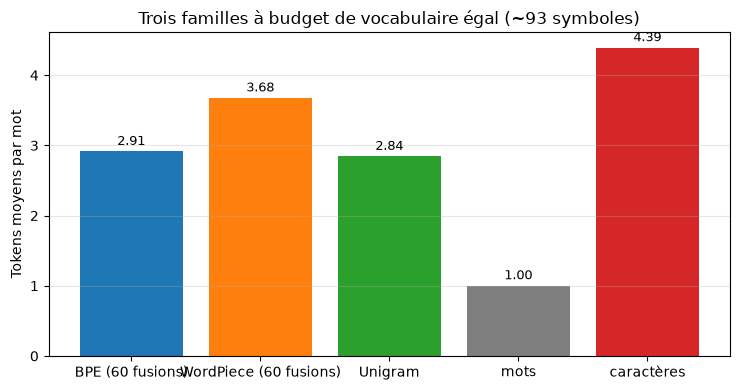

In [7]:
# Graphique du comparatif (output PNG committé, C.2).
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

names = [r[0] for r in rows[2:]] + ['mots', 'caractères']
vals = [r[3] for r in rows[2:]] + [rows[0][3], rows[1][3]]
plt.figure(figsize=(7.5, 4))
bars = plt.bar(names, vals,
               color=['tab:blue', 'tab:orange', 'tab:green', 'tab:gray', 'tab:red'])
for bar, v in zip(bars, vals):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.05, f'{v:.2f}',
             ha='center', va='bottom', fontsize=9)
plt.ylabel('Tokens moyens par mot')
plt.title('Trois familles à budget de vocabulaire égal (~93 symboles)')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## 6. Parité contre la bibliothèque réelle

Nos trois familles sont des **copies pédagogiques déclarées** — le but est de voir le critère à l'œil. La vérification honnête est de confronter les jouets à l'**organe natif** : la bibliothèque [`tokenizers`](https://huggingface.co/docs/tokenizers) (le moteur Rust derrière HuggingFace), qui sait **entraîner** WordPiece et Unigram. On l'entraîne sur le même corpus de mots, au même budget, et on compare.

Puis deux tokenizers de **modèles réels**, pour situer l'échelle :

- **DistilBERT** — un WordPiece réel, entraîné sur l'anglais. Son pipeline commence par un **normalizer** qui minuscule et **retire les accents** : `dépourvue` devient `de ##pour ##vu ##e`. La leçon : le normalizer fait partie du tokenizer, et une information peut être perdue **avant** la découpe.
- **Qwen** — le BPE réel multilingue du 04 (248 044 symboles), pour la continuité.

(Convention : le WordPiece réel préfixe `##` aux pièces non initiales ; nos jouets marquent la fin de mot par `</w>` — deux notations de la même idée de position.)

In [8]:
# La bibliothèque réelle entraîne WordPiece et Unigram sur le MÊME corpus.
from tokenizers import Tokenizer, models, trainers

V = 93
lib_wp = Tokenizer(models.WordPiece(unk_token='[UNK]'))
lib_wp.train_from_iterator(WORDS, trainer=trainers.WordPieceTrainer(
    vocab_size=V, min_frequency=2, show_progress=False, special_tokens=[]))
lib_ug = Tokenizer(models.Unigram())
lib_ug.train_from_iterator(WORDS, trainer=trainers.UnigramTrainer(
    vocab_size=V, show_progress=False, special_tokens=[]))

def lib_pieces(tok, w):
    # '##' marque une pièce non initiale (convention WordPiece réelle) ; on le retire pour comparer.
    return [t.replace('##', '') for t in tok.encode(w).tokens]

print(f"Bibliothèque tokenizers, entraînée sur le même corpus, budget {V} :")
print(f"  WordPiece : vocabulaire {lib_wp.get_vocab_size()}")
print(f"  Unigram   : vocabulaire {lib_ug.get_vocab_size()}")
print()
print(f"{'mot':<12}{'jouet BPE':<24}{'jouet WP':<24}{'jouet UG':<22}{'lib WP':<20}{'lib UG'}")
for w in test_words:
    print(f"{w:<12}{str(BPE_encode(w))[:22]:<24}{str(WP_encode(w))[:22]:<24}"
          f"{str(UG_encode(w))[:20]:<22}{str(lib_pieces(lib_wp, w))[:18]:<20}{str(lib_pieces(lib_ug, w))[:20]}")
print()
print(f"{'tokenizer':<24}{'vocab':>7}{'tokens':>9}{'tokens/mot':>12}")
for name, enc, vsize in [
    ('jouet BPE', BPE_encode, len(MERGES_BPE) + len(CHARS)),
    ('jouet WordPiece', WP_encode, len(MERGES_WP) + len(CHARS)),
    ('jouet Unigram', UG_encode, len(final_counts)),
    ('lib WordPiece', lambda w: lib_pieces(lib_wp, w), lib_wp.get_vocab_size()),
    ('lib Unigram', lambda w: lib_pieces(lib_ug, w), lib_ug.get_vocab_size()),
]:
    n = sum(len(enc(w)) for w in WORDS)
    print(f"{name:<24}{vsize:>7}{n:>9}{n/len(WORDS):>12.3f}")

Bibliothèque tokenizers, entraînée sur le même corpus, budget 93 :
  WordPiece : vocabulaire 93
  Unigram   : vocabulaire 93

mot         jouet BPE               jouet WP                jouet UG              lib WP              lib UG
corbeau     ['c', 'orbeau']         ['corb', 'e', 'a', 'u'  ['corbea', 'u']       ['c', 'or', 'b', '  ['co', 'rb', 'e', 'a
vous        ['vous']                ['vous']                ['vous']              ['v', 'ous']        ['vo', 'us']
chanté      ['ch', 'an', 't', 'é']  ['chan', 'té']          ['c', 'h', 'a', 'n',  ['ch', 'ant', 'é']  ['chant', 'é']
prêteuse    ['pr', 'êt', 'eu', 'se  ['p', 'r', 'êt', 'e',   ['p', 'r', 'ê', 'te'  ['p', 'r', 'ê', 't  ['p', 'r', 'ête', 'u
renard      ['renard']              ['r', 'e', 'n', 'a', '  ['renard']            ['r', 'en', 'ar',   ['ren', 'ar', 'd']
fromage     ['f', 'ro', 'm', 'age'  ['fromag', 'e']         ['fromag', 'e']       ['f', 'r', 'o', 'm  ['f', 'ro', 'm', 'ag
dépourvue   ['dé', 'p', 'our', 'v'  ['dép',

**Lecture chiffrée — la bibliothèque confirme l'ordre : UG 812 < BPE 871 < WP 979, et devance chaque jouet.** La lib fait mieux que nos jouets sur les deux familles qu'elle entraîne — WordPiece **3,274** tokens/mot contre 3,676, Unigram **2,716** contre 2,843 — l'écart vient des régularisations du vrai entraînement (initialisation, découpe initiale, élagage par vraisemblance exacte). Mais le point qui valide les jouets est l'**ordre** : Unigram devant BPE devant WordPiece, identique au nôtre, aux mêmes places relatives. La parité n'est pas le byte-à-byte — les fragments diffèrent, la lib produit `chant + é` quand notre Unigram rend `c+h+a+n+t+é` — c'est la reproduction du phénomène : mécanismes fidèles, chiffres du même ordre, même classement.

In [9]:
# Les tokenizers de modèles réels : le WordPiece anglais de DistilBERT, le BPE de Qwen.
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()   # silence l'avertissement de quota HF Hub (bénin)
import logging as _logging
_logging.getLogger('huggingface_hub').setLevel(_logging.ERROR)
bert = AutoTokenizer.from_pretrained('distilbert/distilbert-base-uncased')
qwen = AutoTokenizer.from_pretrained('Qwen/Qwen3.5-0.8B')

print(f"DistilBERT : {type(bert).__name__}, vocabulaire {bert.vocab_size} "
      f"(WordPiece, entraîné sur l'anglais)")
print(f"Qwen       : {type(qwen).__name__}, vocabulaire {qwen.vocab_size} (BPE multilingue)")
print()
print(f"{'mot':<12}{'DistilBERT (WordPiece réel)':<40}{'Qwen (BPE réel, ids)'}")
for w in ['corbeau', 'dépourvue', 'chanté', 'strawberry']:
    print(f"{w:<12}{str(bert.tokenize(w)):<40}{str(qwen.encode(w))[:44]}")

DistilBERT : BertTokenizer, vocabulaire 30522 (WordPiece, entraîné sur l'anglais)
Qwen       : Qwen2Tokenizer, vocabulaire 248044 (BPE multilingue)

mot         DistilBERT (WordPiece réel)             Qwen (BPE réel, ids)
corbeau     ['co', '##rb', '##eau']                 [5816, 195931]
dépourvue   ['de', '##pour', '##vu', '##e']         [164497, 52689, 20841]
chanté      ['chant', '##e']                        [11345, 933]
strawberry  ['strawberry']                          [485, 654, 14911]


### Le normalizer de DistilBERT efface les accents avant la découpe

`dépourvue → ['de', '##pour', '##vu', '##e']` : le `é` a disparu **avant** la tokenisation — le normalizer du pipeline BERT minuscule et retire les accents (modèle anglais, 30 522 pièces), et la table de découpe ne voit que `depourvue`. L'information accentuelle est perdue pour le modèle quoi qu'on fasse ensuite : **le tokenizer n'est pas juste la table de découpe, c'est le pipeline entier** (normalizer, découpe, table). Le reste de la table situe les échelles : `strawberry` tient en **1 pièce** chez DistilBERT (mot anglais fréquent) contre 3 ids chez Qwen ; `chanté` fait 2 partout, mais Qwen (248 044 pièces, multilingue) couvre le français accentué quand BERT le dégrade.


## 7. L'effet multilingue sur le coût

Un tokenizer apprend la langue de son corpus d'entraînement — c'est une conséquence directe des sections précédentes : les pièces qui survivent sont celles du corpus. La question de coût : **que paie un texte écrit dans une autre langue ?**

On prend une ligne de fable, en trois versions — l'original français, une traduction anglaise et une traduction espagnole (traductions simples faites pour ce notebook ; le texte source est domaine public) — et on compte les tokens avec **deux compteurs** :

- **Qwen réel** (BPE multilingue, 248 044 symboles) — texte normalisé joint, comme au 04 §7 ;
- **notre BPE-60 jouet** (français uniquement) — mot à mot, il ne connaît pas les espaces.

Les deux traductions disent *la même chose* : si les compteurs divergent par langue, la différence est le coût du **contrat de langue** du tokenizer, pas du contenu.

In [10]:
# Le même contenu en trois langues, deux compteurs, la facture.
lignes = {
    'fr': "Le corbeau sur un arbre perché tient un fromage dans son bec",
    'en': "The crow perched on a tree holds a cheese in his beak",
    'es': "El cuervo posado en un árbol tiene un queso en su pico",
}

def norm_words(p):
    return re.findall(r"[a-zà-ÿ'éèêëïôöûüç0-9-]+", p.lower())

print(f"{'langue':<7}{'mots':>5} | {'Qwen réel':>9} {'tok/mot':>8} | {'BPE jouet (fr)':>15} {'tok/mot':>8} | {'surcoût jouet':>13}")
for lg, txt in lignes.items():
    ws = norm_words(txt)
    q = len(qwen.encode(' '.join(ws)))
    b = sum(len(BPE_encode(w)) for w in ws)
    print(f"{lg:<7}{len(ws):>5} | {q:>9} {q/len(ws):>8.2f} | {b:>15} {b/len(ws):>8.2f} | {b/q:>12.2f}x")

langue  mots | Qwen réel  tok/mot |  BPE jouet (fr)  tok/mot | surcoût jouet
fr        12 |        13     1.08 |              30     2.50 |         2.31x
en        12 |        14     1.17 |              35     2.92 |         2.50x
es        12 |        14     1.17 |              36     3.00 |         2.57x


**Lecture chiffrée — le Qwen reste plat (1,08-1,17 tokens/mot), le jouet français grimpe (2,50 → 3,00).** FR : 13 tokens Qwen contre 30 pour le jouet (surcoût ×2,31). EN : 14 contre 35 (×2,50). ES : 14 contre 36 (×2,57). Deux lectures. (1) Le compteur multilingue est **indifférent à la langue** — entraîné sur les trois, il tient chaque version à ~1,1 token/mot : c'est ce que paie son vocabulaire de 248 044 pièces. (2) Le jouet reste le plus compact **dans sa langue** (2,50) et paie chaque sortie de son corpus : +17 % en anglais, +20 % en espagnol. L'écart EN/ES (2,92 contre 3,00) est trop fin pour être interprété — le signal net est **FR contre les deux autres**. C'est le contrat de langue : à vocabulaire fixé, changer de langue sans changer de tokenizer coûte un surcoût mesurable, croissant avec la distance du corpus d'entraînement.

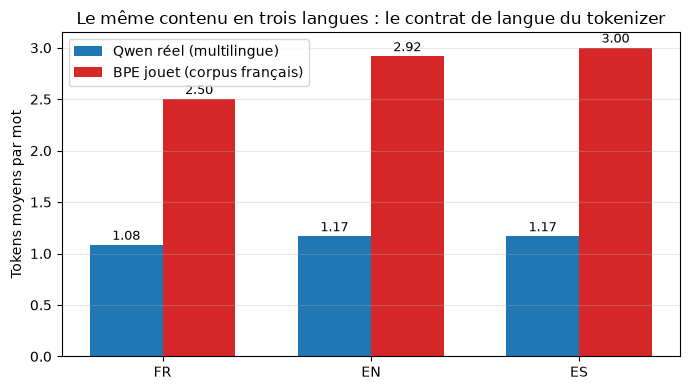

In [11]:
# Graphique : tokens par mot, par langue et par tokenizer (output PNG committé, C.2).
langs = list(lignes)
qwen_rates, toy_rates = [], []
for lg in langs:
    ws = norm_words(lignes[lg])
    qwen_rates.append(len(qwen.encode(' '.join(ws))) / len(ws))
    toy_rates.append(sum(len(BPE_encode(w)) for w in ws) / len(ws))

x = range(len(langs))
w_ = 0.35
plt.figure(figsize=(7, 4))
plt.bar([i - w_/2 for i in x], qwen_rates, w_, label='Qwen réel (multilingue)', color='tab:blue')
plt.bar([i + w_/2 for i in x], toy_rates, w_, label='BPE jouet (corpus français)', color='tab:red')
for i, v in enumerate(qwen_rates):
    plt.text(i - w_/2, v + 0.05, f'{v:.2f}', ha='center', fontsize=9)
for i, v in enumerate(toy_rates):
    plt.text(i + w_/2, v + 0.05, f'{v:.2f}', ha='center', fontsize=9)
plt.xticks(list(x), [l.upper() for l in langs])
plt.ylabel('Tokens moyens par mot')
plt.title('Le même contenu en trois langues : le contrat de langue du tokenizer')
plt.legend()
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## 8. Exercices

Les exercices suivants laissent la main à l'étudiant : entraîner, faire varier, prédire puis vérifier.

### Exercice 1 — WordPiece sur un autre corpus : ce que la cohésion voit et que la fréquence ignore

**Contexte.** La section 3 a montré que BPE et WordPiece, sur les fables, partagent une partie de leurs fusions mais divergent sur d'autres : la fréquence élève les terminaisons communes, la cohésion élève les paires modérément fréquentes mais inséparables.

**Objectif.** Ré-entraîner `train_bpe` et `train_wordpiece` sur un corpus français **de votre choix** (vos propres phrases suffisent), afficher les 12 premières fusions de chacun, et repérer au moins une fusion que WordPiece fait **plus tôt** que BPE — puis expliquer son score (`freq(ab)` élevé, `freq(a)` et `freq(b)` faibles).

**Indices** :
- découper en mots avec la regex de la cellule du corpus, puis `train_bpe(vos_mots, 18)` et `train_wordpiece(vos_mots, 18)` ;
- pour expliquer une fusion : recompter `pair_counts` et `sym_counts` à la main sur les premières itérations, et calculer `freq(ab)/(freq(a)·freq(b))` pour la paire choisie et pour la paire la plus fréquente ;
- un mot rare répété trois fois est un bon générateur de paires cohésives.

In [12]:
# Exercice 1 — WordPiece vs BPE sur votre corpus : une fusion que la cohésion fait plus tôt ?
# → écrire ici votre implémentation ou votre réponse.
print("Exercice 1 a completer")

Exercice 1 a completer


### Exercice 2 — Le budget de l'Unigram : où est le genou ?

**Contexte.** La section 5 a comparé les familles **à budget égal** (93). Le 04 §6 avait montré que la courbe du BPE est concave : chaque fusion rapporte moins que la précédente. L'Unigram a-t-il le même profil quand on fait varier son budget ?

**Objectif.** Refaire l'élagage de la section 4 pour `TARGET_VOCAB` = 60, 75, 93, 110, 130 (les autres paramètres inchangés), mesurer les tokens/mot à chaque budget, et situer le genou — puis comparer au profil du BPE du 04 §6.

**Indices** :
- reprendre `prune(piece_counts, k)` puis `em_refit(...)` pour chaque `k` — les candidats déjà EM-revus (`piece_counts`) sont réutilisables tel quel ;
- afficher `k` et `tokens/mot` en tableau, comme la cellule du 04 §6 ;
- attention : l'EM final peut laisser le vocabulaire **sous** le budget demandé (les pièces inutilisées meurent) — rapporter la taille effective, pas la cible.

In [13]:
# Exercice 2 — tokens/mot de l'Unigram pour TARGET_VOCAB = 60, 75, 93, 110, 130 : où est le genou ?
# → écrire ici votre implémentation ou votre réponse.
result = None  # TODO etudiant
print("Exercice 2 a completer")

Exercice 2 a completer


### Exercice 3 — Prédire puis vérifier : une quatrième langue, et l'allemand

**Contexte.** La section 7 a mesuré le contrat de langue sur trois langues : le jouet français paie cher l'anglais, moins cher l'espagnol. Une quatrième langue au profil morphologique différent — l'allemand et ses mots composés — devrait amplifier le phénomène.

**Objectif.** Traduire la ligne de la fable en allemand (par exemple *« Der Rabe, der auf einem Baum saß, hielt einen Käse im Schnabel »*), **prédire au papier** le classement des quatre langues par tokens/mot pour le BPE jouet ET pour le Qwen réel, puis **vérifier par la mesure**. Expliquer l'écart entre les deux classements.

**Indices** :
- prediction : quels mots allemands partagent leur racine avec le français ? quels sont les composés longs inconnus du corpus ?
- mesure : réutiliser la cellule de la section 7 avec `'de'` en plus, colonnes identiques ;
- l'écart attendu : le jouet ne connaît QUE les fragments français — un mot allemand inconnu retombe sur ses caractères et digrammes ; Qwen, lui, a vu l'allemand à l'entraînement… vérifiez si son vocabulaire contient « Schnabel » ou « Baum » entiers (`'Schnabel' in qwen.vocab` ou `qwen.encode('Schnabel')`).

In [14]:
# Exercice 3 — L'allemand au banc : prédire le classement, puis vérifier les deux compteurs.
# → écrire ici votre prédiction puis votre mesure.
print("Exercice 3 a completer")

Exercice 3 a completer


## Continuer le parcours

WordPiece et Unigram produisent, comme le BPE du 04, l'**unité de compte** que consomme toute la série ; l'étape suivante reste le stockage et la recherche des vecteurs bâtis sur ces tokens :

- [`05-Stockage-Vectoriel.ipynb`](05-Stockage-Vectoriel.ipynb) — stockage local, suite aval directe ;
- [`04-Tokenisation-From-Scratch.ipynb`](04-Tokenisation-From-Scratch.ipynb) — retour à la mécanique BPE et au coût du chunking ;
- [`03-Embeddings-From-Scratch.ipynb`](03-Embeddings-From-Scratch.ipynb) — la couche en aval immédiate des tokens : l'espace vectoriel.

Cette cellule de navigation conclut le notebook sans modifier les exercices ni leurs outputs.